# La misma pulsera, cuatro historias

**Jornada 1 · Bloque 1.3 · Tipos y estructura del dato (granularidad) · Demo en directo**

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (en inglés, *Runtime → Run all*); la primera vez tarda unos segundos en descargar los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*. Luego mueve los controles. No hace falta tocar el código: está escondido y solo carga los datos y dibuja. Si quieres verlo, pulsa los tres puntos que aparecen en las celdas ocultas.

In [1]:
# Preparación: busca la carpeta del proyecto, carga el estilo del curso y los datos.
# No hace falta tocar nada.
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/, scripts/estilo.py y cuadernos/laboratorio.py."""
    aqui = Path.cwd()
    candidatas = [aqui, *aqui.parents,
                  Path("/content/cursos-analitica-datos"),               # Colab, subida a mano
                  Path("/content/drive/MyDrive/cursos-analitica-datos")]  # Colab, desde Drive
    for carpeta in candidatas:
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "cuadernos" / "laboratorio.py").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab, descarga una vez el material público del curso
        import subprocess
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro el proyecto: abre este cuaderno desde la carpeta cuadernos/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos"):  # ../scripts y la carpeta de este cuaderno
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))

import ipywidgets as widgets
from IPython.display import display

import estilo  # paleta, tipografía y formato numérico español del curso
import laboratorio as lab  # cálculos y gráficos de estos cuadernos

try:  # en Google Colab, los controles necesitan activar este gestor
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

ESTILO = {"description_width": "initial"}
BOTONES = {"description_width": "initial", "button_width": "auto"}

pulsera = lab.cargar_pulsera(DATOS)
print(f"Datos listos: {len(pulsera['hora']):,} horas de pasos de 2025".replace(",", "."))

Datos listos: 8.760 horas de pasos de 2025


## La pregunta

Lucía ha llevado una pulsera de actividad todo 2025. ¿Es sedentaria, deportista de fin de semana o
montañera? Depende de cómo sumes sus pasos. Lucía, por su parte, cree que es las tres cosas.

## El experimento

Elige cómo agregar los pasos: por hora, por día, por semana o por mes. En la vista por hora puedes
elegir la semana: prueba la del 3 de marzo, alguna de agosto y la del 17 de noviembre.

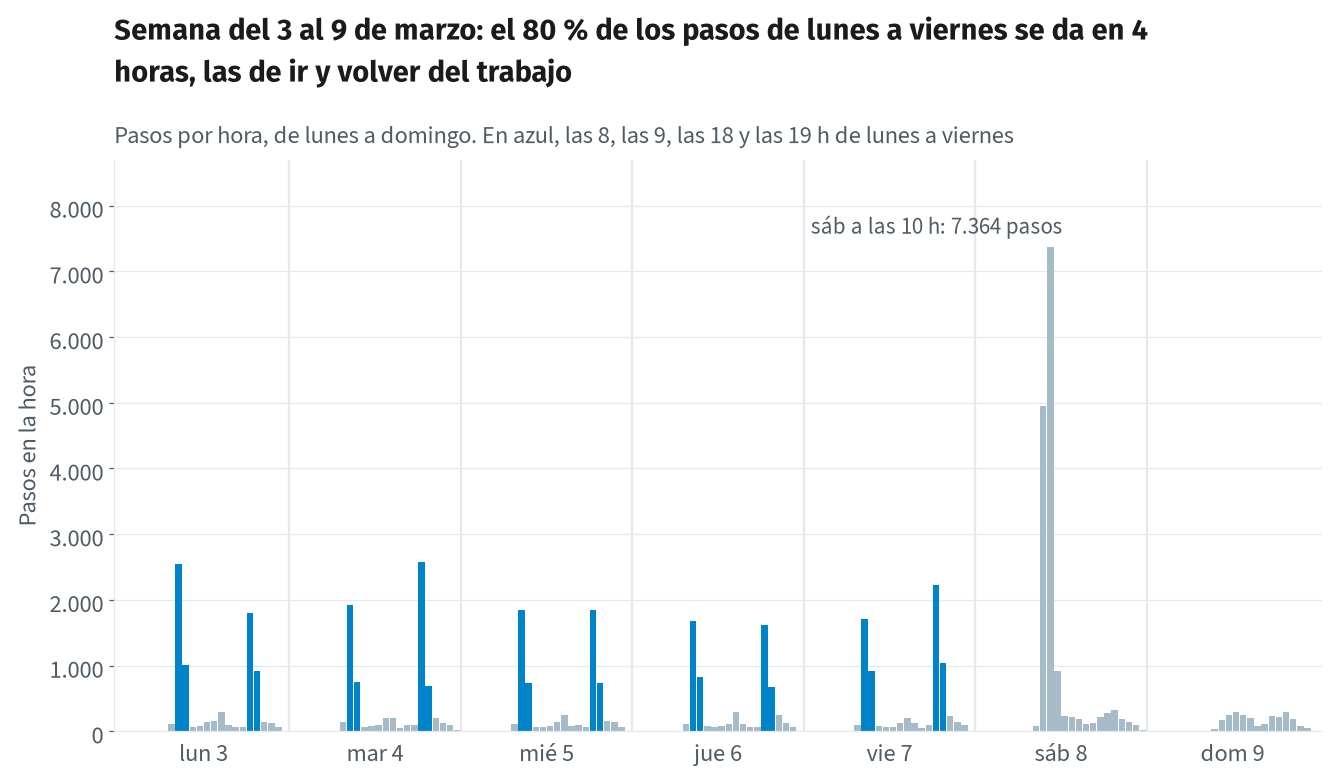

In [2]:
# El experimento: los mismos pasos, agregados de cuatro formas.
nivel = widgets.ToggleButtons(
    options=[("Por hora", "hora"), ("Por día", "dia"), ("Por semana", "semana"), ("Por mes", "mes")],
    value="hora", description="Agregar:", style=BOTONES)
semana = widgets.Dropdown(options=lab.semanas_pulsera(), value="2025-03-03",
                          description="Semana (solo por hora):", style=ESTILO)


def dibujar(nivel, semana):
    lab.mostrar(lab.dibujar_granularidad(pulsera, nivel, semana))


# La semana solo cuenta en la vista por hora.
nivel.observe(lambda cambio: setattr(semana, "disabled", cambio["new"] != "hora"), names="value")

grafico = widgets.interactive_output(dibujar, {"nivel": nivel, "semana": semana})
display(widgets.VBox([nivel, semana, grafico]))

## Qué observar

1. Por hora, en la semana del 3 de marzo, ¿qué diagnóstico harías? ¿Cambia si eliges la del 11 de agosto
   o la del 17 de noviembre?
2. Por día, ¿qué patrón aparece que en la vista por hora no se veía?
3. Por semana salen dos sorpresas. ¿Cuál de las dos casi desaparece en la vista por mes? ¿Por qué?
4. Si fueras su médica, ¿qué granularidad pedirías? ¿Y si fueras la marca de la pulsera preparando el
   anuncio del verano?

## Mensaje clave

> **El mismo dato, agregado de otra forma, cuenta otra historia.**

Las cuatro conclusiones son ciertas a su escala. La pregunta decide la granularidad, y no al revés.

## Para curiosos

En el curso avanzado se trabaja con series de alta frecuencia de verdad: huecos, cambios de hora y cómo
agregar sin perder lo que importa. Aquí basta con preguntarse siempre: «¿sumado cómo?».